# HU-07 · Prototipo del recomendador basado en contenido

Prototipo de la fase 2 de HU-07. Calcula la similitud entre los productos del catálogo de prueba
(`appPrincipal/fixtures/catalogo.csv`) con **TF-IDF** y **similitud del coseno**, sobre la categoría,
la plataforma, la familia de la plataforma y el género. Es el mismo cálculo que hará
`recomendaciones.calcular_similitudes()` en Django (fase 3), y sirve de material para el informe.

El notebook muestra:

1. cómo se representa cada producto como un documento de etiquetas;
2. la matriz TF-IDF y el peso que pone el IDF a cada etiqueta;
3. la matriz de similitud y su mapa de calor;
4. ejemplos de recomendación («para Elden Ring PS5 recomienda…»);
5. el efecto de la etiqueta de familia y el efecto del IDF;
6. los empates y la limitación de Funko Pop y Amiibo;
7. un prototipo del perfil del cliente (vista = 1, carrito = 2, compra = 3).

No usa la base de datos: lee el CSV directamente, así que se puede ejecutar en cualquier computador con
las dependencias de `notebooks/requirements.txt`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from django.utils.text import slugify
from matplotlib.colors import LinearSegmentedColormap
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
CATALOGO = RAIZ / 'appPrincipal' / 'fixtures' / 'catalogo.csv'

# código de plataforma -> familia (copia de PLATAFORMAS en la migración 0011)
FAMILIAS = {
    'ps5': 'playstation', 'ps4': 'playstation', 'ps3': 'playstation', 'ps2': 'playstation',
    'ps1': 'playstation', 'psvita': 'playstation', 'psp': 'playstation',
    'xboxseries': 'xbox', 'xboxone': 'xbox', 'xbox360': 'xbox',
    'switch': 'nintendo', 'wiiu': 'nintendo', 'wii': 'nintendo', '3ds': 'nintendo',
    'pc': 'pc',
}

# colores de los gráficos: rampa secuencial de un solo tono (claro = 0, oscuro = 1)
TINTA, TINTA_SECUNDARIA, SUPERFICIE = '#0b0b0b', '#52514e', '#fcfcfb'
AZUL = '#2a78d6'
RAMPA = LinearSegmentedColormap.from_list(
    'similitud', [SUPERFICIE, '#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])
plt.rcParams.update({
    'figure.facecolor': SUPERFICIE, 'axes.facecolor': SUPERFICIE, 'savefig.facecolor': SUPERFICIE,
    'text.color': TINTA, 'axes.labelcolor': TINTA_SECUNDARIA, 'axes.edgecolor': '#c3c2b7',
    'xtick.color': TINTA_SECUNDARIA, 'ytick.color': TINTA_SECUNDARIA,
    'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10,
})
pd.set_option('display.max_colwidth', 60)

## 1. El catálogo de prueba

115 productos reales armados por el equipo (no se usó Faker para los productos). Los videojuegos tienen
plataforma y género; las consolas y los accesorios solo plataforma; los Funko Pop y los Amiibo no tienen
ninguno de los dos, tal como lo definen `Categoria.requiere_plataforma` y `Categoria.requiere_genero`.

In [2]:
catalogo = pd.read_csv(CATALOGO, dtype=str, keep_default_na=False, encoding='utf-8-sig')
catalogo['familia'] = catalogo['plataforma'].map(FAMILIAS).fillna('')
# etiqueta legible para tablas y gráficos: "Elden Ring (ps5)"
catalogo['producto'] = catalogo.apply(
    lambda f: f"{f['nombre']} ({f['plataforma']})" if f['plataforma'] else f['nombre'], axis=1)

print(f'{len(catalogo)} productos')
catalogo.groupby('categoria', sort=False).agg(
    productos=('nombre', 'size'),
    con_plataforma=('plataforma', lambda s: (s != '').sum()),
    con_genero=('genero', lambda s: (s != '').sum()),
)

115 productos


,productos,con_plataforma,con_genero
categoria,,,
Videojuegos,89,89,89
Consolas,7,7,0
Accesorios,9,9,0
Funko Pop,6,0,0
Amiibo,4,0,0


In [3]:
# videojuegos por plataforma y género: el mismo juego aparece en varias plataformas a propósito
juegos = catalogo[catalogo['categoria'] == 'Videojuegos']
pd.crosstab(juegos['plataforma'], juegos['genero'], margins=True, margins_name='Total')

genero,Acción,Aventura,Carreras,Deportes,Estrategia,Puzzle,RPG,Simulación,Terror,Total
plataforma,,,,,,,,,,
3ds,0,0,1,0,0,0,1,0,0,2
pc,0,0,0,1,3,1,1,2,1,9
ps3,1,1,1,0,0,0,0,0,0,3
ps4,2,4,0,1,0,0,3,1,2,13
ps5,6,5,2,2,1,1,6,1,4,28
switch,3,6,1,2,2,2,4,2,0,22
xboxone,1,1,0,0,0,0,0,0,0,2
xboxseries,2,0,2,1,0,0,3,1,1,10
Total,15,17,7,7,6,4,18,7,8,89


## 2. Cada producto como un documento de etiquetas

Cada atributo se convierte en una etiqueta con prefijo, para que «pc» la plataforma y «pc» la familia
sean palabras distintas. Los nombres pasan por `slugify` (el mismo que usa `seed_catalogo`), que quita
tildes y espacios: `Acción → gen_accion`, `Funko Pop → cat_funko_pop`.

La etiqueta de **familia** (`fam_playstation`, `fam_xbox`, `fam_nintendo`, `fam_pc`) se agrega para que
un juego de PS5 se parezca más a uno de PS4 que a uno de Switch. Los atributos vacíos no generan etiqueta.

In [4]:
def etiqueta(prefijo, valor):
    return f"{prefijo}_{slugify(valor).replace('-', '_')}"


def documento(fila, con_familia=True):
    atributos = [('cat', fila['categoria']), ('plat', fila['plataforma'])]
    if con_familia:
        atributos.append(('fam', fila['familia']))
    atributos.append(('gen', fila['genero']))
    return ' '.join(etiqueta(prefijo, valor) for prefijo, valor in atributos if valor)


catalogo['documento'] = catalogo.apply(documento, axis=1)
ejemplos = ['Elden Ring (ps5)', 'Elden Ring (xboxseries)', 'Consola PlayStation 5 Slim Digital (ps5)',
            'Control DualSense Blanco (ps5)', 'Funko Pop Kratos (God of War)', 'Amiibo Mario (Super Mario)']
catalogo.set_index('producto').loc[ejemplos, ['documento']]

,documento
producto,
Elden Ring (ps5),cat_videojuegos plat_ps5 fam_playstation gen_rpg
Elden Ring (xboxseries),cat_videojuegos plat_xboxseries fam_xbox gen_rpg
Consola PlayStation 5 Slim Digital (ps5),cat_consolas plat_ps5 fam_playstation
Control DualSense Blanco (ps5),cat_accesorios plat_ps5 fam_playstation
Funko Pop Kratos (God of War),cat_funko_pop
Amiibo Mario (Super Mario),cat_amiibo


## 3. La matriz TF-IDF

Se usa `TfidfVectorizer` de scikit-learn con su configuración por defecto, salvo que cada palabra separada
por espacios es una etiqueta (`token_pattern=r'\S+'`). El peso de la etiqueta *t* en el producto *d* es

$$w_{t,d} = \mathrm{tf}(t,d)\cdot \mathrm{idf}(t), \qquad \mathrm{idf}(t) = \ln\frac{1+n}{1+\mathrm{df}(t)} + 1$$

donde *n* es el número de productos y df(*t*) el número de productos que tienen la etiqueta. Después cada
vector se normaliza a largo 1 (norma L2).

**Nota para el informe:** cada etiqueta aparece a lo más una vez por producto, así que tf = 1 siempre y,
en la práctica, **el peso lo pone solo el IDF**: una etiqueta rara (un género o una plataforma con pocos
productos) pesa más que una común (`cat_videojuegos`).

In [5]:
vectorizador = TfidfVectorizer(token_pattern=r'\S+', lowercase=False)
tfidf = vectorizador.fit_transform(catalogo['documento'])
etiquetas = vectorizador.get_feature_names_out()

print(f'Matriz TF-IDF: {tfidf.shape[0]} productos × {tfidf.shape[1]} etiquetas, '
      f'{tfidf.nnz} valores distintos de cero ({tfidf.nnz / np.prod(tfidf.shape):.1%})')
print('tf máximo de una etiqueta en un producto:',
      max(pd.Series(d.split()).value_counts().max() for d in catalogo['documento']))

idf = pd.DataFrame({
    'productos_con_la_etiqueta': np.asarray((tfidf > 0).sum(axis=0)).ravel(),
    'idf': vectorizador.idf_,
}, index=etiquetas).sort_values('idf')
idf.round(3)

Matriz TF-IDF: 115 productos × 26 etiquetas, 414 valores distintos de cero (13.8%)
tf máximo de una etiqueta en un producto: 1


,productos_con_la_etiqueta,idf
cat_videojuegos,89,1.254
fam_playstation,50,1.822
plat_ps5,32,2.257
fam_nintendo,30,2.320
plat_switch,27,2.421
gen_rpg,18,2.809
gen_aventura,17,2.863
gen_accion,15,2.981
fam_xbox,15,2.981
plat_ps4,15,2.981


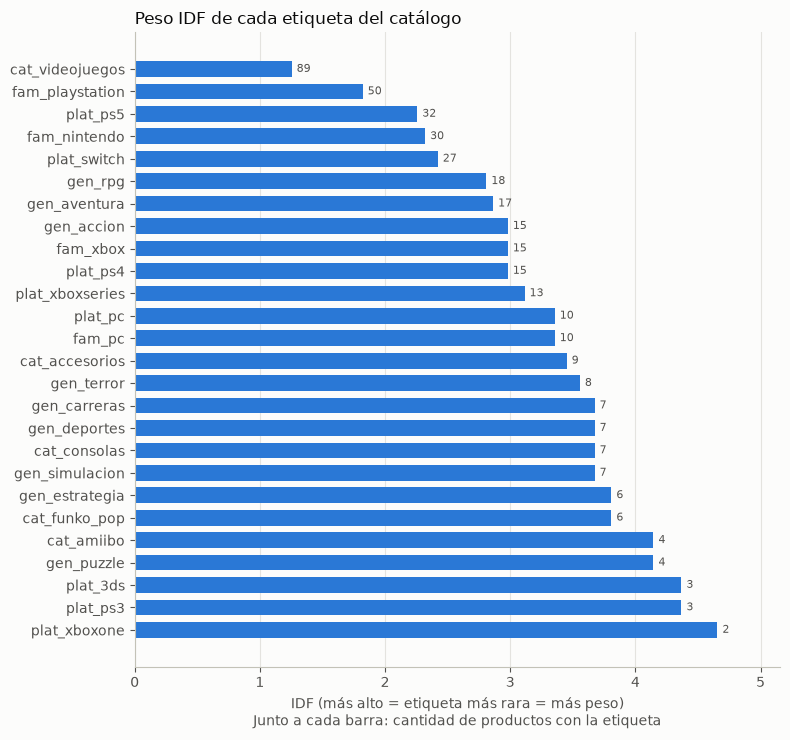

In [6]:
fig, ax = plt.subplots(figsize=(8, 7.5))
ax.barh(idf.index, idf['idf'], color=AZUL, height=0.7)
ax.invert_yaxis()
ax.set_xlabel('IDF (más alto = etiqueta más rara = más peso)\n'
              'Junto a cada barra: cantidad de productos con la etiqueta')
ax.set_title('Peso IDF de cada etiqueta del catálogo', loc='left', fontsize=12)
ax.grid(axis='x', color='#e4e3df', linewidth=0.8)
ax.set_axisbelow(True)
for i, (valor, df) in enumerate(zip(idf['idf'], idf['productos_con_la_etiqueta'])):
    ax.text(valor + 0.04, i, f'{df}', va='center', fontsize=8, color=TINTA_SECUNDARIA)
ax.set_xlim(0, idf['idf'].max() + 0.5)
plt.tight_layout()
plt.show()

In [7]:
# el vector de Elden Ring (ps5): solo sus 4 etiquetas tienen peso, y el género pesa más que la categoría
def vector(producto, matriz=tfidf, nombres=etiquetas):
    fila = matriz[catalogo.index[catalogo['producto'] == producto][0]].toarray().ravel()
    return pd.Series(fila, index=nombres)[lambda s: s > 0].sort_values(ascending=False).round(3)

vector('Elden Ring (ps5)').to_frame('peso')

,peso
gen_rpg,0.664
plat_ps5,0.534
fam_playstation,0.431
cat_videojuegos,0.297


## 4. La matriz de similitud del coseno

Como los vectores ya tienen largo 1, la similitud del coseno entre dos productos es el producto punto de
sus vectores: 1 si tienen exactamente las mismas etiquetas, 0 si no comparten ninguna. La matriz es
simétrica y su diagonal es 1.

En el mapa de calor los productos están ordenados por categoría, familia, plataforma y género, así que
los bloques oscuros son grupos de productos parecidos.

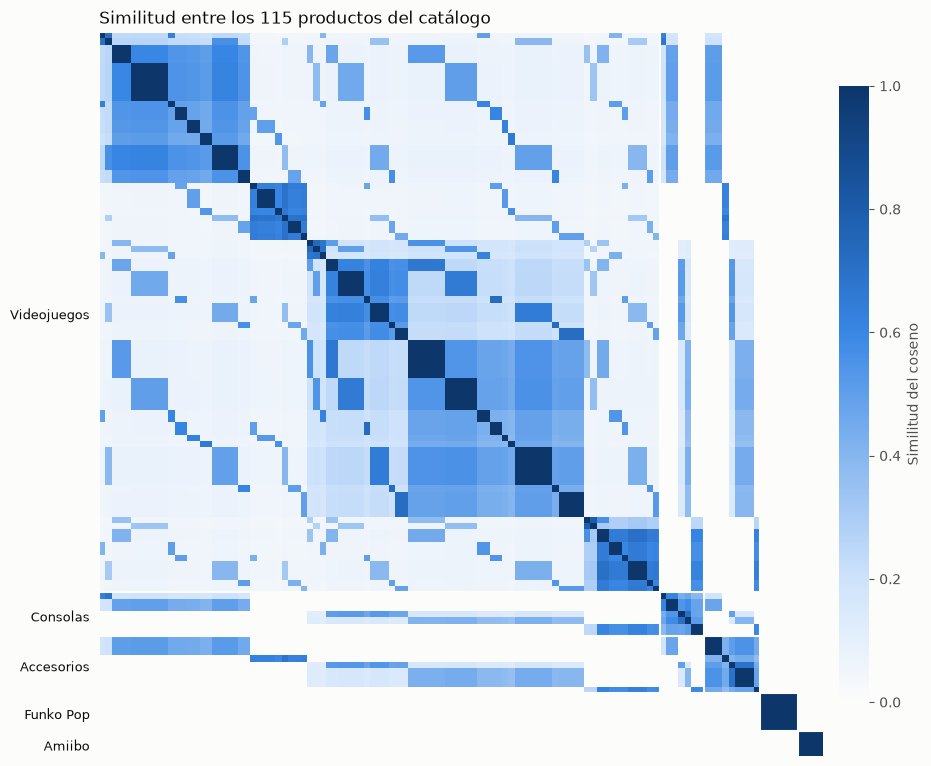

In [8]:
similitud = cosine_similarity(tfidf)
# las categorías en el orden del CSV (Videojuegos, Consolas, Accesorios, Funko Pop, Amiibo)
posicion_categoria = {c: i for i, c in enumerate(catalogo['categoria'].unique())}
orden = catalogo.assign(posicion=catalogo['categoria'].map(posicion_categoria)).sort_values(
    ['posicion', 'familia', 'plataforma', 'genero', 'nombre']).index

fig, ax = plt.subplots(figsize=(9, 8))
imagen = ax.imshow(similitud[np.ix_(orden, orden)], cmap=RAMPA, vmin=0, vmax=1, interpolation='nearest')
# líneas y nombres de cada categoría
categorias = catalogo.loc[orden, 'categoria'].to_numpy()
limites = [0] + [i for i in range(1, len(categorias)) if categorias[i] != categorias[i - 1]] + [len(categorias)]
for inicio, fin in zip(limites, limites[1:]):
    ax.axhline(inicio - 0.5, color=SUPERFICIE, linewidth=1.5)
    ax.axvline(inicio - 0.5, color=SUPERFICIE, linewidth=1.5)
    ax.text(-2, (inicio + fin) / 2, categorias[inicio], ha='right', va='center', fontsize=9, color=TINTA)
ax.set_xticks([])
ax.set_yticks([])
ax.spines[:].set_visible(False)
barra = fig.colorbar(imagen, ax=ax, fraction=0.04, pad=0.02)
barra.set_label('Similitud del coseno')
barra.outline.set_visible(False)
ax.set_title(f'Similitud entre los {len(catalogo)} productos del catálogo', loc='left', fontsize=12)
plt.tight_layout()
plt.show()

Un acercamiento a un grupo de productos permite leer los valores: el mismo juego en dos plataformas, juegos
de la misma familia, de otra familia, una consola, un accesorio y un Funko.

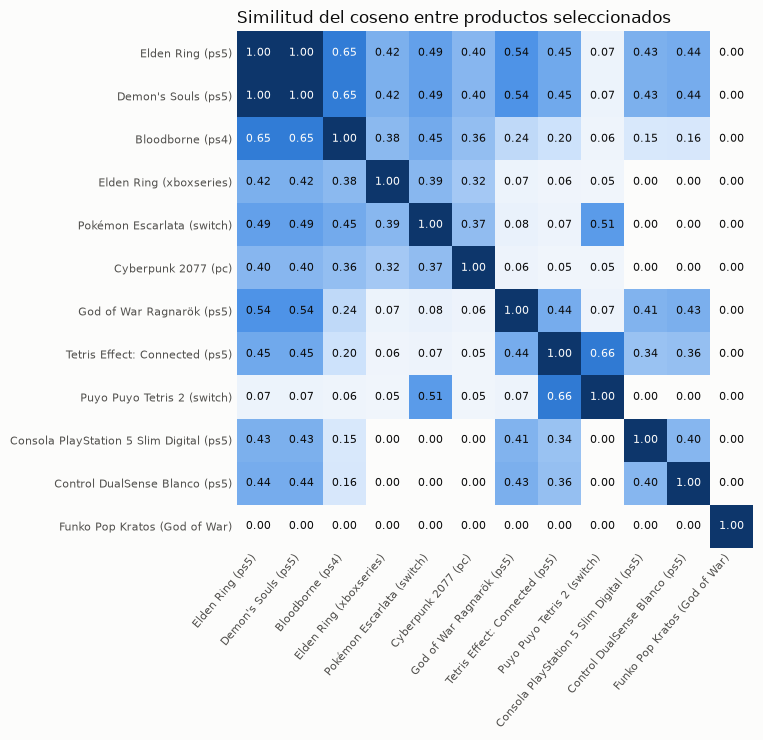

In [9]:
seleccion = ['Elden Ring (ps5)', "Demon's Souls (ps5)", 'Bloodborne (ps4)', 'Elden Ring (xboxseries)',
             'Pokémon Escarlata (switch)', 'Cyberpunk 2077 (pc)', 'God of War Ragnarök (ps5)',
             'Tetris Effect: Connected (ps5)', 'Puyo Puyo Tetris 2 (switch)',
             'Consola PlayStation 5 Slim Digital (ps5)', 'Control DualSense Blanco (ps5)',
             'Funko Pop Kratos (God of War)']
indices = [catalogo.index[catalogo['producto'] == p][0] for p in seleccion]
submatriz = similitud[np.ix_(indices, indices)]

fig, ax = plt.subplots(figsize=(9, 7.5))
ax.imshow(submatriz, cmap=RAMPA, vmin=0, vmax=1)
for i in range(len(indices)):
    for j in range(len(indices)):
        valor = submatriz[i, j]
        ax.text(j, i, f'{valor:.2f}', ha='center', va='center', fontsize=8,
                color=SUPERFICIE if valor > 0.55 else TINTA)
ax.set_xticks(range(len(seleccion)), seleccion, rotation=50, ha='right', fontsize=8)
ax.set_yticks(range(len(seleccion)), seleccion, fontsize=8)
ax.spines[:].set_visible(False)
ax.tick_params(length=0)
ax.set_title('Similitud del coseno entre productos seleccionados', loc='left', fontsize=12)
plt.tight_layout()
plt.show()

## 5. Ejemplos de recomendación

`similares()` devuelve los *n* productos más parecidos a uno, sin incluirlo a él mismo. En Django se
guardará el top 10 de cada producto en `SimilitudProducto`. Los empates se ordenan por nombre para que el
resultado sea reproducible (ver la sección 8).

In [10]:
def similares(producto, n=10, matriz=None):
    matriz = similitud if matriz is None else matriz
    i = catalogo.index[catalogo['producto'] == producto][0]
    resultado = catalogo.assign(puntaje=matriz[i]).drop(index=i)
    resultado = resultado.sort_values(['puntaje', 'producto'], ascending=[False, True]).head(n)
    return resultado[['producto', 'categoria', 'genero', 'puntaje']].round({'puntaje': 3}).reset_index(drop=True)

print('Para Elden Ring (PS5) recomienda:')
similares('Elden Ring (ps5)')

Para Elden Ring (PS5) recomienda:


,producto,categoria,genero,puntaje
0,Baldur's Gate 3 (ps5),Videojuegos,RPG,1.000
1,Demon's Souls (ps5),Videojuegos,RPG,1.000
2,Final Fantasy VII Rebirth (ps5),Videojuegos,RPG,1.000
3,Final Fantasy XVI (ps5),Videojuegos,RPG,1.000
4,Hogwarts Legacy (ps5),Videojuegos,RPG,1.000
5,Bloodborne (ps4),Videojuegos,RPG,0.649
6,Persona 5 Royal (ps4),Videojuegos,RPG,0.649
7,The Witcher 3: Wild Hunt Complete Edition (ps4),Videojuegos,RPG,0.649
8,Astro Bot (ps5),Videojuegos,Aventura,0.554
9,Ghost of Tsushima Director's Cut (ps5),Videojuegos,Aventura,0.554


In [11]:
# un género raro: el puzzle pesa tanto que el otro juego de puzzle supera a los de su misma plataforma
print('Para Tetris Effect: Connected (PS5) recomienda:')
similares('Tetris Effect: Connected (ps5)', n=6)

Para Tetris Effect: Connected (PS5) recomienda:


,producto,categoria,genero,puntaje
0,Captain Toad: Treasure Tracker (switch),Videojuegos,Puzzle,0.657
1,Puyo Puyo Tetris 2 (switch),Videojuegos,Puzzle,0.657
2,Portal 2 (pc),Videojuegos,Puzzle,0.560
3,Baldur's Gate 3 (ps5),Videojuegos,RPG,0.453
4,Demon's Souls (ps5),Videojuegos,RPG,0.453
5,Elden Ring (ps5),Videojuegos,RPG,0.453


In [12]:
print('Para la consola PlayStation 5 recomienda:')
similares('Consola PlayStation 5 Slim Digital (ps5)', n=6)

Para la consola PlayStation 5 recomienda:


,producto,categoria,genero,puntaje
0,Consola PlayStation 4 Slim 1 TB (reacondicionada) (ps4),Consolas,,0.709
1,Consola Nintendo Switch Lite (switch),Consolas,,0.580
2,Consola Nintendo Switch OLED (switch),Consolas,,0.580
3,Consola Xbox Series S (xboxseries),Consolas,,0.509
4,Consola Xbox Series X (xboxseries),Consolas,,0.509
5,Consola New Nintendo 3DS XL (reacondicionada) (3ds),Consolas,,0.468


In [13]:
print('Para el control DualSense recomienda:')
similares('Control DualSense Blanco (ps5)', n=6)

Para el control DualSense recomienda:


,producto,categoria,genero,puntaje
0,Audífonos inalámbricos Pulse 3D (ps5),Accesorios,,1.000
1,Control DualSense Midnight Black (ps5),Accesorios,,1.000
2,Control DualShock 4 Negro (ps4),Accesorios,,0.688
3,Control Pro Nintendo Switch (switch),Accesorios,,0.549
4,Estuche de transporte Nintendo Switch (switch),Accesorios,,0.549
5,Joy-Con Neón (par) (switch),Accesorios,,0.549


## 6. Efecto de la etiqueta de familia

Se repite el cálculo sin la etiqueta `fam_…` y se compara la similitud promedio entre pares de
videojuegos según qué comparten. Sin la familia, un juego de PS5 y uno de PS4 del mismo género se parecen
exactamente lo mismo que uno de PS5 y uno de Switch del mismo género; con la familia, el de PS4 queda más
cerca.

In [14]:
tfidf_sin_familia = TfidfVectorizer(token_pattern=r'\S+', lowercase=False).fit_transform(
    catalogo.apply(documento, axis=1, con_familia=False))
similitud_sin_familia = cosine_similarity(tfidf_sin_familia)


def relacion(a, b):
    if a['plataforma'] == b['plataforma']:
        plataforma = 'misma plataforma'
    elif a['familia'] == b['familia']:
        plataforma = 'otra plataforma, misma familia'
    else:
        plataforma = 'otra familia'
    return plataforma, 'mismo género' if a['genero'] == b['genero'] else 'otro género'


pares = []
indices_juegos = juegos.index.to_numpy()
for posicion, i in enumerate(indices_juegos):
    for j in indices_juegos[posicion + 1:]:
        plataforma, genero = relacion(catalogo.loc[i], catalogo.loc[j])
        pares.append((plataforma, genero, similitud_sin_familia[i, j], similitud[i, j]))
pares = pd.DataFrame(pares, columns=['plataforma', 'genero', 'sin familia', 'con familia'])
efecto_familia = pares.groupby(['genero', 'plataforma'], sort=False).agg(
    pares=('con familia', 'size'), sin_familia=('sin familia', 'mean'), con_familia=('con familia', 'mean'))
efecto_familia.sort_index().round(3)

pares  sin_familia  con_familia
genero       plataforma                                                     
mismo género misma plataforma                   96        1.000        1.000
             otra familia                      323        0.580        0.451
             otra plataforma, misma familia     87        0.563        0.631
otro género  misma plataforma                  677        0.424        0.534
             otra familia                     2269        0.077        0.060
             otra plataforma, misma familia    464        0.078        0.218

In [15]:
# lo mismo con un ejemplo concreto
comparacion = pd.DataFrame({
    'sin familia': [similitud_sin_familia[catalogo.index[catalogo['producto'] == 'Elden Ring (ps5)'][0],
                                          catalogo.index[catalogo['producto'] == p][0]] for p in seleccion[1:6]],
    'con familia': [similitud[catalogo.index[catalogo['producto'] == 'Elden Ring (ps5)'][0],
                              catalogo.index[catalogo['producto'] == p][0]] for p in seleccion[1:6]],
}, index=pd.Index(seleccion[1:6], name='Elden Ring (ps5) comparado con'))
comparacion.round(3)

,sin familia,con familia
Elden Ring (ps5) comparado con,,
Demon's Souls (ps5),1.000,1.000
Bloodborne (ps4),0.579,0.649
Elden Ring (xboxseries),0.567,0.423
Pokémon Escarlata (switch),0.634,0.492
Cyberpunk 2077 (pc),0.545,0.396


## 7. Efecto del IDF

Se compara con una versión **sin IDF** (`use_idf=False`): todas las etiquetas pesan lo mismo y la
similitud solo cuenta cuántas etiquetas se comparten. Para cada videojuego se toman sus 5 recomendaciones
y se mide qué porcentaje comparte el género y qué porcentaje comparte la plataforma.

In [16]:
tfidf_sin_idf = TfidfVectorizer(token_pattern=r'\S+', lowercase=False, use_idf=False).fit_transform(
    catalogo['documento'])
similitud_sin_idf = cosine_similarity(tfidf_sin_idf)


def coherencia(matriz, n=5):
    comparte_genero = comparte_plataforma = total = 0
    for producto in juegos['producto']:
        original = catalogo.loc[catalogo['producto'] == producto].iloc[0]
        for _, recomendado in similares(producto, n=n, matriz=matriz).iterrows():
            fila = catalogo.loc[catalogo['producto'] == recomendado['producto']].iloc[0]
            comparte_genero += fila['genero'] == original['genero']
            comparte_plataforma += fila['plataforma'] == original['plataforma']
            total += 1
    return {'comparte género': comparte_genero / total, 'comparte plataforma': comparte_plataforma / total}


pd.DataFrame({'sin IDF': coherencia(similitud_sin_idf), 'con IDF': coherencia(similitud)}).map('{:.1%}'.format)

,sin IDF,con IDF
comparte género,50.6%,70.1%
comparte plataforma,91.5%,73.0%


In [17]:
# el caso de Tetris Effect (PS5) con y sin IDF
pd.concat({'sin IDF': similares('Tetris Effect: Connected (ps5)', n=5, matriz=similitud_sin_idf)[['producto', 'puntaje']],
           'con IDF': similares('Tetris Effect: Connected (ps5)', n=5)[['producto', 'puntaje']]}, axis=1)

sin IDF                                          con IDF  \
                   producto puntaje                                 producto   
0         Alan Wake 2 (ps5)    0.75  Captain Toad: Treasure Tracker (switch)   
1           Astro Bot (ps5)    0.75              Puyo Puyo Tetris 2 (switch)   
2     Baldur's Gate 3 (ps5)    0.75                            Portal 2 (pc)   
3  Black Myth: Wukong (ps5)    0.75                    Baldur's Gate 3 (ps5)   
4          Dead Space (ps5)    0.75                      Demon's Souls (ps5)   

           
  puntaje  
0   0.657  
1   0.657  
2   0.560  
3   0.453  
4   0.453

## 8. Empates y la limitación de Funko Pop y Amiibo

Dos productos con exactamente las mismas etiquetas tienen similitud 1.0 y no hay forma de distinguirlos
con estos atributos. Pasa con los videojuegos de la misma plataforma y el mismo género (los 6 RPG de PS5),
y sobre todo con los **Funko Pop y los Amiibo**: como no tienen plataforma ni género, su documento es solo
la categoría y todos los de una misma categoría son idénticos entre sí.

In [18]:
figuras = catalogo[catalogo['categoria'].isin(['Funko Pop', 'Amiibo'])]
# nombres cortos para que la tabla quepa: "Funko Pop Kratos (God of War)" -> "Funko Kratos"
cortos = figuras['nombre'].str.replace('Funko Pop', 'Funko').str.split(' (', regex=False).str[0]
pd.DataFrame(similitud[np.ix_(figuras.index, figuras.index)], index=cortos, columns=cortos).round(2)

nombre,Funko Kratos,Funko Mario,Funko Link,Funko Pikachu,Funko Master Chief,Funko Ellie,Amiibo Link,Amiibo Mario,Amiibo Inkling,Amiibo Pikachu
nombre,,,,,,,,,,
Funko Kratos,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0
Funko Mario,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0
Funko Link,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0
Funko Pikachu,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0
Funko Master Chief,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0
Funko Ellie,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0
Amiibo Link,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0
Amiibo Mario,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0
Amiibo Inkling,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0


In [19]:
# grupos de productos con el mismo documento (similitud 1.0 entre ellos)
grupos = catalogo.groupby('documento').agg(productos=('producto', 'size'), ejemplo=('producto', 'first'))
grupos = grupos[grupos['productos'] > 1].sort_values('productos', ascending=False)
print(f"{grupos['productos'].sum()} de {len(catalogo)} productos tienen al menos un gemelo con similitud 1.0, "
      f"en {len(grupos)} grupos.")
grupos.head(10)

89 de 115 productos tienen al menos un gemelo con similitud 1.0, en 28 grupos.


,productos,ejemplo
documento,,
cat_funko_pop,6,Funko Pop Kratos (God of War)
cat_videojuegos plat_switch fam_nintendo gen_aventura,6,The Legend of Zelda: Tears of the Kingdom (switch)
cat_videojuegos plat_ps5 fam_playstation gen_rpg,6,Elden Ring (ps5)
cat_videojuegos plat_ps5 fam_playstation gen_accion,6,God of War Ragnarök (ps5)
cat_videojuegos plat_ps5 fam_playstation gen_aventura,5,Horizon Forbidden West (ps5)
cat_amiibo,4,Amiibo Link (Tears of the Kingdom)
cat_videojuegos plat_switch fam_nintendo gen_rpg,4,Pokémon Escarlata (switch)
cat_videojuegos plat_ps5 fam_playstation gen_terror,4,Resident Evil 4 (ps5)
cat_videojuegos plat_ps4 fam_playstation gen_aventura,4,The Last of Us Parte II (ps4)


In [20]:
# ¿cuántos productos tienen un empate justo en el corte del top 10?
def empate_en_el_corte(i, n=10):
    puntajes = np.sort(np.delete(similitud[i], i))[::-1]
    return np.isclose(puntajes[n - 1], puntajes[n]) if len(puntajes) > n else False

con_empate = sum(empate_en_el_corte(i) for i in catalogo.index)
print(f'{con_empate} de {len(catalogo)} productos tienen un empate en la posición 10 del top 10.')

93 de 115 productos tienen un empate en la posición 10 del top 10.


## 9. Prototipo del perfil del cliente

Para un cliente que autorizó el uso de sus datos de navegación, el perfil es el promedio ponderado de los
vectores TF-IDF de los productos con que interactuó (vista = 1, carrito = 2, compra = 3, sumando si hubo
varias interacciones con el mismo producto). El perfil se compara por coseno con todo el catálogo y se
excluye lo que el cliente ya compró.

Ejemplo inventado a mano (la simulación con Faker es parte de la fase 4): un cliente que vio dos RPG de
Switch y Mario Kart, agregó Zelda: Tears of the Kingdom al carrito y compró Pokémon Escarlata.

In [21]:
PESOS = {'vista': 1, 'carrito': 2, 'compra': 3}


def recomendar_perfil(interacciones, n=5):
    pesos = np.zeros(len(catalogo))
    for producto, tipo in interacciones:
        pesos[catalogo.index[catalogo['producto'] == producto][0]] += PESOS[tipo]
    perfil = np.asarray(tfidf.T @ pesos / pesos.sum()).reshape(1, -1)
    resultado = catalogo.assign(puntaje=cosine_similarity(perfil, tfidf).ravel())
    comprados = [producto for producto, tipo in interacciones if tipo == 'compra']
    resultado = resultado[~resultado['producto'].isin(comprados)]
    resultado = resultado.sort_values(['puntaje', 'producto'], ascending=[False, True]).head(n)
    return resultado[['producto', 'genero', 'puntaje']].round({'puntaje': 3}).reset_index(drop=True)


cliente = [
    ('Xenoblade Chronicles 3 (switch)', 'vista'),
    ('Pokémon Púrpura (switch)', 'vista'),
    ('Mario Kart 8 Deluxe (switch)', 'vista'),
    ('The Legend of Zelda: Tears of the Kingdom (switch)', 'carrito'),
    ('Pokémon Escarlata (switch)', 'compra'),
]
recomendar_perfil(cliente)

,producto,genero,puntaje
0,Hogwarts Legacy (switch),RPG,0.959
1,Pokémon Púrpura (switch),RPG,0.959
2,Xenoblade Chronicles 3 (switch),RPG,0.959
3,Kirby y la tierra olvidada (switch),Aventura,0.795
4,Luigi's Mansion 3 (switch),Aventura,0.795


## 10. Costo del cálculo

El cálculo completo (vectorizar y comparar todos contra todos) se mide para decidir si en Django conviene
recalcular todo cada vez que cambia el catálogo o solo el producto modificado.

In [22]:
%timeit cosine_similarity(TfidfVectorizer(token_pattern=r'\S+', lowercase=False).fit_transform(catalogo['documento']))

2.06 ms ± 169 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


## 11. Conclusiones para el informe y para la fase 3

**El IDF pone todo el peso.** Como tf = 1 en todas las etiquetas, el peso de cada una depende solo de cuán
rara es. `cat_videojuegos` (89 productos) es la que menos pesa (IDF 1,25) y las más raras, como
`plat_xboxone` (2 productos) o `gen_puzzle` (4), son las que más pesan. En Elden Ring (PS5) el género pesa
más que la plataforma, la familia y la categoría (0,66 > 0,53 > 0,43 > 0,30, ya normalizados).

**El IDF desplaza las recomendaciones hacia el género.** En el top 5 de los videojuegos, con IDF el 70,1 %
de las recomendaciones comparte el género (50,6 % sin IDF) y el 73,0 % comparte la plataforma (91,5 % sin
IDF). Sin IDF, Tetris Effect (PS5) recomienda cualquier juego de PS5 con el mismo puntaje (0,75); con IDF
recomienda primero los otros tres juegos de puzzle. A cambio, alrededor de un cuarto de las
recomendaciones es de otra plataforma, lo que conviene revisar en la evaluación de la fase 4.

**La familia de plataforma cumple su objetivo.** Entre juegos del mismo género, la similitud promedio sube
de 0,563 a 0,631 cuando son de la misma familia y baja de 0,580 a 0,451 cuando son de otra familia. Elden
Ring (PS5) pasa a parecerse más a Bloodborne (PS4, 0,649) que a Pokémon Escarlata (Switch, 0,492); sin la
familia era al revés (0,579 contra 0,634). El mismo juego en otra familia queda lejos (Elden Ring de Xbox,
0,423), lo que es razonable: a un cliente con PS5 no le sirve la versión de Xbox.

**Hay muchos empates.** 89 de los 115 productos tienen al menos otro con exactamente las mismas etiquetas,
y en 93 productos hay un empate justo en la posición 10 del top 10. Con solo tres atributos es inevitable.
Por eso la fase 3 necesita un criterio de desempate explícito y reproducible (por ejemplo, unidades
vendidas y después el id), en vez de depender del orden en que la base de datos devuelve las filas.

**Limitación de Funko Pop y Amiibo.** Su documento es solo la categoría: dentro de su categoría todos
tienen similitud 1,0 y con el resto del catálogo 0, así que nunca se recomiendan desde la ficha de un
videojuego (el Funko de Kratos no aparece junto a God of War) y entre ellos el orden lo decide solo el
desempate. Se declara como limitación en el informe; una mejora futura sería un atributo de franquicia o
usar la descripción, que hoy no se usa.

**El perfil del cliente funciona con el arranque en frío resuelto.** El cliente del ejemplo, que solo miró
y compró juegos de Switch, recibe RPG de Switch (0,959) y después aventuras de Switch (0,795), sin el juego
que ya compró. Como solo se excluye lo comprado, sí puede recibir productos que ya vio o tiene en el
carrito (Xenoblade Chronicles 3 aparece tercero).

**Para la integración en Django (fase 3):**

- usar la misma configuración: `TfidfVectorizer(token_pattern=r'\S+', lowercase=False)`, etiquetas con
  prefijo, `slugify` y la familia tomada de `Plataforma.familia`;
- guardar el top 10 por producto en `SimilitudProducto` con el desempate definido;
- el cálculo completo toma milisegundos con este catálogo, así que recalcular todo al cambiar el catálogo
  es más simple y seguro que recalcular solo el producto modificado.